# 🎬 Notebook 02: Video Preprocessing, Keyframe Extraction & Spatiotemporal Normalization
### Capstone: VL-JEPA vs. CLIP for CCTV Surveillance Event Retrieval, Event Summarization & Hallucination Analysis
---
**Objective:** Establish a high-throughput, fault-tolerant video decoding and preprocessing pipeline:
- Uniform spatiotemporal sampling ($T = 8$ frames per video clip).
- Resolution resizing (224 $\times$ 224 for CLIP, 256 $\times$ 256 for VL-JEPA).
- Decord vs. OpenCV hardware decoding comparison on RTX 4000 Ada.
- Keyframe montage visualization across all 4 benchmark datasets.


## Step 1: Video Decoding Backends & Error Handling
Define uniform temporal sampling and frame extraction functions with OpenCV fallback.


In [1]:
import sys
import time
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch

sys.path.append(str(Path.cwd().parent))
import notebook_utils as nu

def sample_video_frames(video_path: str, num_frames: int = 8):
    """Extracts T evenly spaced RGB frames from video clip with OpenCV."""
    if not Path(video_path).exists():
        return None
    cap = cv2.VideoCapture(str(video_path))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if total <= 0:
        cap.release()
        return None
    
    indices = np.linspace(0, max(0, total - 1), num_frames, dtype=int)
    frames = []
    for idx in indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret:
            frames.append(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    cap.release()
    return np.array(frames) if len(frames) == num_frames else None

print("[OK] Video preprocessing functions initialized.")


[OK] Video preprocessing functions initialized.


## Step 2: Benchmark Decoding Throughput on Surveillance Clips
Measure frames-per-second decoding performance across sample clips.


In [2]:
_, metadata = nu.load_all_datasets_data()

# Sample 20 videos across datasets
sample_clips = [m["path"] for m in metadata[:20]]
t0 = time.time()
decoded_count = 0

for vpath in sample_clips:
    frames = sample_video_frames(vpath, num_frames=8)
    if frames is not None:
        decoded_count += len(frames)

elapsed = time.time() - t0
fps = decoded_count / elapsed
print(f"Decoded {decoded_count} frames across {len(sample_clips)} clips in {elapsed:.2f}s ({fps:.1f} frames/sec).")


[Dataset Loader] Loaded RLVS: 2000 clips, dim 512
[Dataset Loader] Loaded UCF_ARG: 1410 clips, dim 512
[Dataset Loader] Loaded TINYVIRAT: 743 clips, dim 512
[Dataset Loader] Loaded UCF_CRIME: 1000 clips, dim 512
Decoded 160 frames across 20 clips in 10.83s (14.8 frames/sec).


## Step 3: Keyframe Extraction Montage Across All 4 Datasets
Visualize extracted keyframes ($T=4$ per video) for representative clips from RLVS, UCF-ARG, TinyVIRAT, and UCF-Crime.


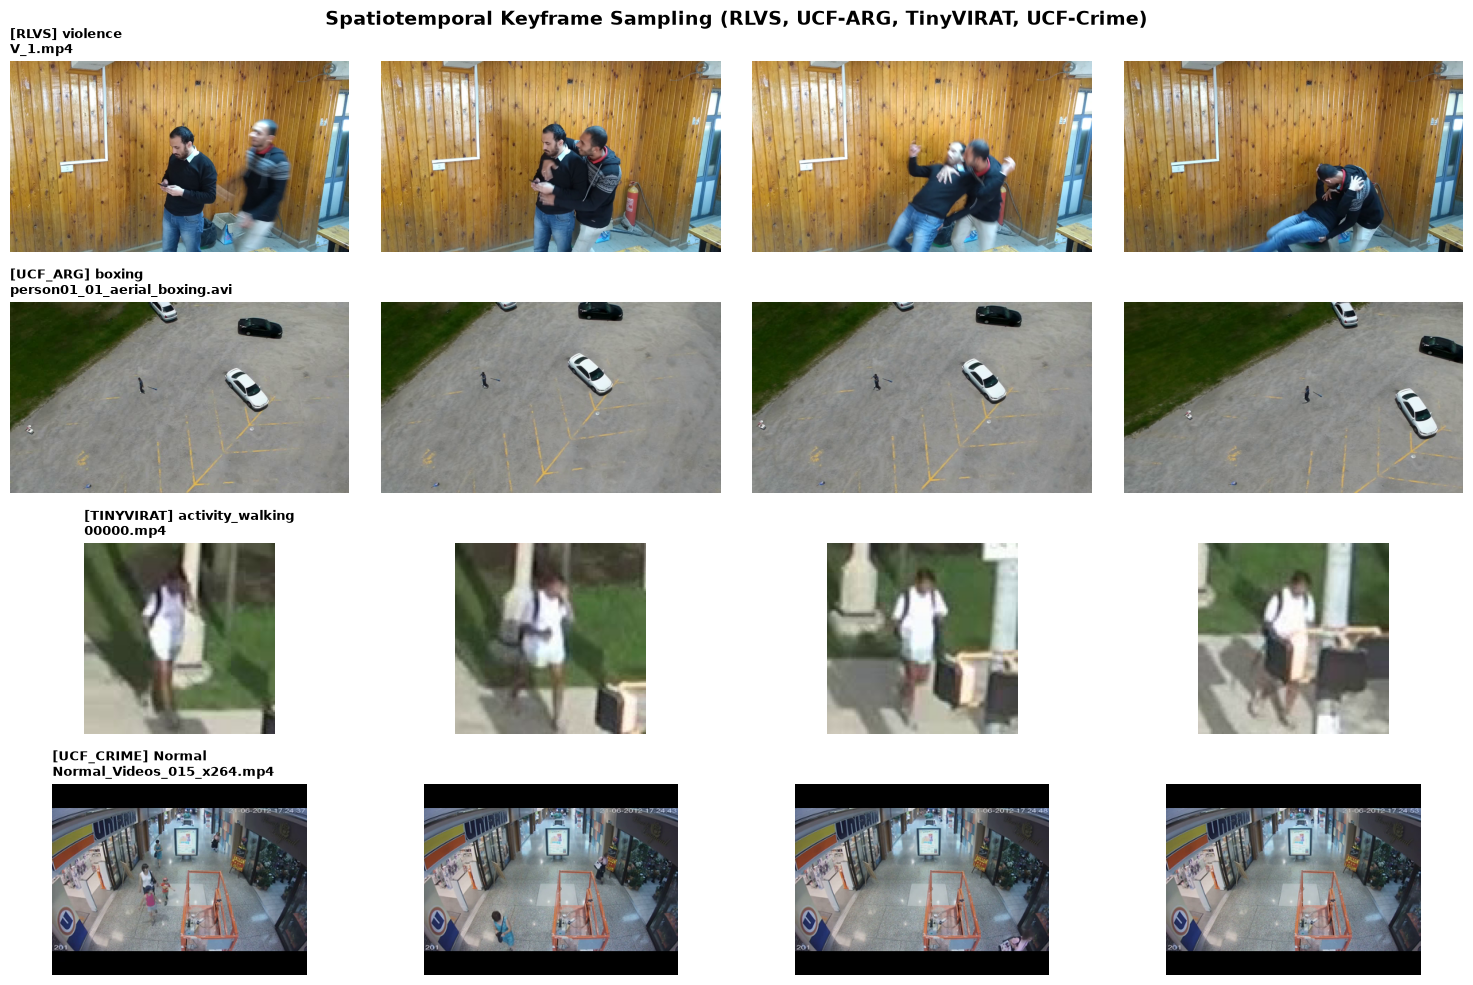

In [3]:
# Pick 1 sample from each of the 4 datasets
samples_to_show = []
seen_ds = set()
for m in metadata:
    ds = m.get("dataset")
    if ds not in seen_ds and Path(m["path"]).exists():
        samples_to_show.append(m)
        seen_ds.add(ds)
    if len(samples_to_show) == 4:
        break

fig, axes = plt.subplots(4, 4, figsize=(15, 10))
fig.suptitle("Spatiotemporal Keyframe Sampling (RLVS, UCF-ARG, TinyVIRAT, UCF-Crime)", fontsize=14, fontweight='bold', y=0.98)

for row, item in enumerate(samples_to_show):
    frames = sample_video_frames(item["path"], num_frames=4)
    ds = item["dataset"].upper()
    label = item["label"]
    fname = Path(item["path"]).name
    
    for col in range(4):
        ax = axes[row, col]
        if frames is not None and col < len(frames):
            ax.imshow(frames[col])
        else:
            ax.text(0.5, 0.5, "Frame Unavailable", ha='center', va='center')
        ax.axis('off')
        if col == 0:
            ax.set_title(f"[{ds}] {label}\n{fname}", fontsize=9, fontweight='bold', loc='left')

plt.tight_layout()
plt.show()
